# Used Car Price Prediction — End-to-End Machine Learning Project
**CodeAlpha Data Science Internship — Task 3**

## 1. Project Overview
This notebook implements a complete, reproducible machine learning pipeline to predict the resale selling price (`Selling_Price`, in Lakhs INR) of used vehicles using the **CarDekho Vehicle Dataset**.

### Workflow Covered
1. **Data Collection & Exploration**: Inspect schema, missing values, duplicates, descriptive statistics, target distribution, and outliers.
2. **Data Cleaning & Preprocessing**: Remove exact duplicates, validate domain constraints without blindly discarding valid extremes, and prevent data leakage via `scikit-learn` pipelines.
3. **Exploratory Data Analysis (EDA)**: Create and save 10 publication-ready visualizations to `outputs/visualizations/`.
4. **Feature Engineering**: Derive `Car_Age` from `Year` and remove redundant/high-cardinality columns (`Year`, `Car_Name`).
5. **Model Training & Comparison**: Evaluate Linear Regression, Decision Tree, Random Forest, Gradient Boosting, and Extra Trees Regressors using 5-fold cross-validation and an 80:20 holdout test split.
6. **Model Evaluation & Diagnostics**: Compute MAE, MSE, RMSE, and R² Score; inspect residual diagnostics and feature importances.
7. **Model Persistence & Prediction**: Save the full fitted pipeline and metadata to `models/best_car_price_model.joblib` and demonstrate real predictions without retraining.

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Ensure project root is on sys.path regardless of where Jupyter is launched
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import TARGET_COLUMN, clean_car_data, load_car_data
from src.evaluate import (
    calculate_regression_metrics,
    extract_feature_importance,
    plot_actual_vs_predicted,
    plot_feature_importance,
    plot_model_comparison,
    plot_residual_distribution,
    plot_residuals_vs_predicted,
)
from src.predict import SAMPLE_CAR_INPUT, predict_car_price
from src.preprocessing import (
    CATEGORICAL_FEATURES,
    NUMERIC_FEATURES,
    REFERENCE_YEAR,
    build_preprocessor,
    engineer_features,
    get_clean_feature_names,
)
from src.train import (
    CV_SPLITS,
    DEFAULT_MODEL_PATH,
    EVAL_PLOTS_DIR,
    OUTPUTS_DIR,
    RANDOM_STATE,
    VIS_PLOTS_DIR,
    train_and_evaluate,
)

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

VIS_PLOTS_DIR.mkdir(parents=True, exist_ok=True)
EVAL_PLOTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project Root : {PROJECT_ROOT}")
print(f"Reference Year for Car_Age : {REFERENCE_YEAR}")

Project Root : E:\CodeAlpha_tasks(2)\CodeAlpha_CarPricePrediction
Reference Year for Car_Age : 2026


## 2. Data Collection and Exploration
We load `dataset/car data.csv` using `load_car_data()` and inspect its structure, data types, missing values, duplicates, descriptive statistics, and extreme values.

In [2]:
raw_df = load_car_data()
print(f"Dataset Shape: {raw_df.shape[0]} rows x {raw_df.shape[1]} columns")
display(raw_df.head())
display(raw_df.tail())

Dataset Shape: 301 rows x 9 columns


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
296,city,2016,9.50,11.6,33988,Diesel,Dealer,Manual,0
297,brio,2015,4.00,5.9,60000,Petrol,Dealer,Manual,0
298,city,2009,3.35,11.0,87934,Petrol,Dealer,Manual,0
299,city,2017,11.50,12.5,9000,Diesel,Dealer,Manual,0
300,brio,2016,5.30,5.9,5464,Petrol,Dealer,Manual,0


In [3]:
print("--- Column Names & Data Types ---")
print(raw_df.dtypes)
print("\n--- Dataset Info ---")
raw_df.info()

--- Column Names & Data Types ---
Car_Name             str
Year               int64
Selling_Price    float64
Present_Price    float64
Kms_Driven         int64
Fuel_Type            str
Seller_Type          str
Transmission         str
Owner              int64
dtype: object

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Seller_Type    301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB


In [4]:
missing_summary = raw_df.isnull().sum().to_frame(name="Missing_Count")
missing_summary["Missing_Pct"] = (missing_summary["Missing_Count"] / len(raw_df)) * 100
print("--- Missing Values Summary ---")
display(missing_summary)

dup_count = int(raw_df.duplicated().sum())
print(f"Exact Duplicate Rows Found: {dup_count}")
if dup_count > 0:
    display(raw_df[raw_df.duplicated(keep=False)].sort_values(by=["Car_Name", "Year"]))

--- Missing Values Summary ---


,Missing_Count,Missing_Pct
Car_Name,0,0.0
Year,0,0.0
Selling_Price,0,0.0
Present_Price,0,0.0
Kms_Driven,0,0.0
Fuel_Type,0,0.0
Seller_Type,0,0.0
Transmission,0,0.0
Owner,0,0.0


Exact Duplicate Rows Found: 2


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
15,ertiga,2016,7.75,10.79,43000,Diesel,Dealer,Manual,0
17,ertiga,2016,7.75,10.79,43000,Diesel,Dealer,Manual,0
51,fortuner,2015,23.00,30.61,40000,Diesel,Dealer,Automatic,0
93,fortuner,2015,23.00,30.61,40000,Diesel,Dealer,Automatic,0


In [5]:
print("--- Descriptive Statistics (All Columns) ---")
display(raw_df.describe(include="all").T)

categorical_cols = raw_df.select_dtypes(include=["object", "string", "category"]).columns.tolist()
numerical_cols = raw_df.select_dtypes(include=["number"]).columns.tolist()
print(f"Categorical Features ({len(categorical_cols)}): {categorical_cols}")
print(f"Numerical Features   ({len(numerical_cols)}): {numerical_cols}")

for col in ["Fuel_Type", "Seller_Type", "Transmission", "Owner"]:
    print(f"\nValue counts for {col}:")
    print(raw_df[col].value_counts())
print(f"\nUnique Car_Name count: {raw_df['Car_Name'].nunique()}")

--- Descriptive Statistics (All Columns) ---


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Car_Name,301,98,city,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,301.0,NaN,NaN,NaN,2013.627907,2.891554,2003.0,2012.0,2014.0,2016.0,2018.0
Selling_Price,301.0,NaN,NaN,NaN,4.661296,5.082812,0.1,0.9,3.6,6.0,35.0
Present_Price,301.0,NaN,NaN,NaN,7.628472,8.644115,0.32,1.2,6.4,9.9,92.6
Kms_Driven,301.0,NaN,NaN,NaN,36947.20598,38886.883882,500.0,15000.0,32000.0,48767.0,500000.0
Fuel_Type,301,3,Petrol,239,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Seller_Type,301,2,Dealer,195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transmission,301,2,Manual,261,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Owner,301.0,NaN,NaN,NaN,0.043189,0.247915,0.0,0.0,0.0,0.0,3.0


Categorical Features (4): ['Car_Name', 'Fuel_Type', 'Seller_Type', 'Transmission']
Numerical Features   (5): ['Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Owner']

Value counts for Fuel_Type:
Fuel_Type
Petrol    239
Diesel     60
CNG         2
Name: count, dtype: int64

Value counts for Seller_Type:
Seller_Type
Dealer        195
Individual    106
Name: count, dtype: int64

Value counts for Transmission:
Transmission
Manual       261
Automatic     40
Name: count, dtype: int64

Value counts for Owner:
Owner
0    290
1     10
3      1
Name: count, dtype: int64

Unique Car_Name count: 98


In [6]:
# Examine target variable (Selling_Price) distribution & outlier bounds
target_stats = raw_df[TARGET_COLUMN].describe()
target_skew = raw_df[TARGET_COLUMN].skew()
print("--- Target Variable (Selling_Price) Summary ---")
print(target_stats)
print(f"Skewness: {target_skew:.4f}")

# IQR-based outlier inspection across key numeric columns
for col in ["Selling_Price", "Present_Price", "Kms_Driven"]:
    q1 = raw_df[col].quantile(0.25)
    q3 = raw_df[col].quantile(0.75)
    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    outliers = raw_df[raw_df[col] > upper]
    print(f"\n{col} | Q1={q1:.2f}, Q3={q3:.2f}, Upper IQR Fence={upper:.2f} -> {len(outliers)} records above fence")

print("\nTop 5 highest Selling_Price records:")
display(raw_df.nlargest(5, "Selling_Price"))

print("\nTop 5 highest Kms_Driven records:")
display(raw_df.nlargest(5, "Kms_Driven"))

invalid_price_rel = raw_df[raw_df["Selling_Price"] >= raw_df["Present_Price"]]
print(f"Records where Selling_Price >= Present_Price: {len(invalid_price_rel)}")

--- Target Variable (Selling_Price) Summary ---
count    301.000000
mean       4.661296
std        5.082812
min        0.100000
25%        0.900000
50%        3.600000
75%        6.000000
max       35.000000
Name: Selling_Price, dtype: float64
Skewness: 2.4934

Selling_Price | Q1=0.90, Q3=6.00, Upper IQR Fence=13.65 -> 17 records above fence

Present_Price | Q1=1.20, Q3=9.90, Upper IQR Fence=22.95 -> 14 records above fence

Kms_Driven | Q1=15000.00, Q3=48767.00, Upper IQR Fence=99417.50 -> 8 records above fence

Top 5 highest Selling_Price records:


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
86,land cruiser,2010,35.0,92.60,78000,Diesel,Dealer,Manual,0
64,fortuner,2017,33.0,36.23,6000,Diesel,Dealer,Automatic,0
63,fortuner,2015,23.5,35.96,47000,Diesel,Dealer,Automatic,0
51,fortuner,2015,23.0,30.61,40000,Diesel,Dealer,Automatic,0
82,innova,2017,23.0,25.39,15000,Diesel,Dealer,Automatic,0



Top 5 highest Kms_Driven records:


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
196,Activa 3g,2008,0.17,0.52,500000,Petrol,Individual,Automatic,0
179,Honda Karizma,2010,0.31,1.05,213000,Petrol,Individual,Manual,0
84,innova,2005,3.49,13.46,197176,Diesel,Dealer,Manual,0
85,camry,2006,2.50,23.73,142000,Petrol,Individual,Automatic,3
77,corolla,2004,1.50,12.35,135154,Petrol,Dealer,Automatic,0


Records where Selling_Price >= Present_Price: 0


### Key Findings from Initial Exploration
- **Dimensions & Schema**: The raw dataset contains **301 records and 9 columns** (`Car_Name`, `Year`, `Selling_Price`, `Present_Price`, `Kms_Driven`, `Fuel_Type`, `Seller_Type`, `Transmission`, `Owner`).
- **Missing Values & Duplicates**: There are **0 missing values** across all columns, and **2 exact duplicate records** (one 2016 `ertiga` pair and one 2015 `fortuner` pair).
- **Vehicle Mix**: `Car_Name` has 98 unique entries spanning both passenger cars (e.g., `city`, `corolla altis`, `fortuner`, `land cruiser`) and two-wheelers (e.g., `Royal Enfield Classic 350`, `Activa 3g`, `Bajaj Pulsar`), explaining why `Present_Price` spans from `0.32` to `92.60` Lakhs INR.
- **Target Distribution**: `Selling_Price` is right-skewed (`mean = 4.66`, `median = 3.60`, `max = 35.00` Lakhs INR).
- **Outliers & Data Integrity**: Every single record satisfies `Selling_Price < Present_Price`. High-end vehicles (`land cruiser` at `92.60` Lakhs showroom price, `fortuner` at `33.00` Lakhs resale) and high-mileage vehicles (`500,000` km `Activa 3g`) are genuine observations rather than corrupted entries, so they should **not** be blindly deleted.

## 3. Data Cleaning and Preprocessing
We apply `clean_car_data()` to strip whitespace, verify numeric dtypes, remove the 2 exact duplicate rows, and validate physical domain bounds (`Present_Price > 0`, `Selling_Price >= 0`, `Kms_Driven >= 0`, `Owner >= 0`).

To prevent **data leakage**, scaling (`StandardScaler`) and categorical encoding (`OneHotEncoder`) are encapsulated inside a `scikit-learn` `ColumnTransformer` and fitted **only** on the training split.

In [7]:
cleaned_df, cleaning_report = clean_car_data(raw_df, max_valid_year=REFERENCE_YEAR)
print("Cleaning Report:")
for k, v in cleaning_report.items():
    print(f"  {k}: {v}")

print(f"\nCleaned Dataset Shape: {cleaned_df.shape}")

Cleaning Report:
  initial_rows: 301
  missing_values_found: 0
  rows_dropped_for_missing: 0
  duplicate_rows_removed: 2
  invalid_domain_rows_removed: 0
  final_rows: 299

Cleaned Dataset Shape: (299, 9)


## 4. Feature Engineering
We derive `Car_Age = REFERENCE_YEAR - Year` (`REFERENCE_YEAR = 2026`), capturing depreciation directly in years.
- **`Year`** is dropped after deriving `Car_Age` because it carries identical linear information in reverse sign.
- **`Car_Name`** (98 unique string labels across 299 rows) is dropped to prevent severe sparse high-cardinality overfitting on a small dataset; vehicle price tier is already strongly captured by `Present_Price`.
- **`Selling_Price`** is strictly separated as target `y` and never included in feature matrix `X`.

In [8]:
eda_df = cleaned_df.copy()
eda_df["Car_Age"] = REFERENCE_YEAR - eda_df["Year"]

X_preview = engineer_features(cleaned_df, reference_year=REFERENCE_YEAR)
y_preview = cleaned_df[TARGET_COLUMN].copy()

print(f"Engineered Feature Matrix Shape: {X_preview.shape}")
print(f"Target Vector Shape           : {y_preview.shape}")
display(X_preview.head())

Engineered Feature Matrix Shape: (299, 7)
Target Vector Shape           : (299,)


,Present_Price,Kms_Driven,Owner,Car_Age,Fuel_Type,Seller_Type,Transmission
0,5.59,27000,0,12,Petrol,Dealer,Manual
1,9.54,43000,0,13,Diesel,Dealer,Manual
2,9.85,6900,0,9,Petrol,Dealer,Manual
3,4.15,5200,0,15,Petrol,Dealer,Manual
4,6.87,42450,0,12,Diesel,Dealer,Manual


## 5. Exploratory Data Analysis (EDA)
Below are the required EDA visualizations saved to `outputs/visualizations/` and displayed inline.

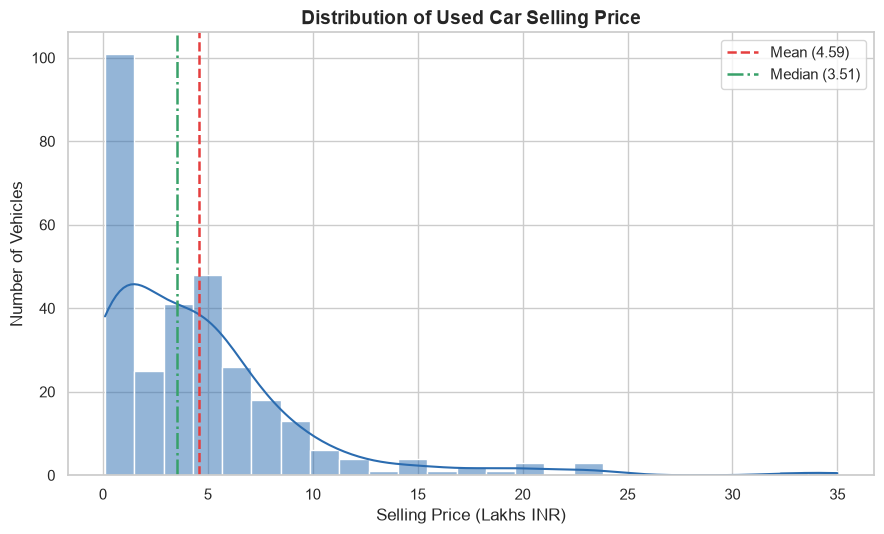

In [9]:
# 1. Selling price distribution
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.histplot(eda_df["Selling_Price"], bins=25, kde=True, color="#2b6cb0", ax=ax)
mean_val = eda_df["Selling_Price"].mean()
median_val = eda_df["Selling_Price"].median()
ax.axvline(mean_val, color="#e53e3e", linestyle="--", linewidth=1.8, label=f"Mean ({mean_val:.2f})")
ax.axvline(median_val, color="#38a169", linestyle="-.", linewidth=1.8, label=f"Median ({median_val:.2f})")
ax.set_title("Distribution of Used Car Selling Price", fontsize=14, fontweight="bold")
ax.set_xlabel("Selling Price (Lakhs INR)")
ax.set_ylabel("Number of Vehicles")
ax.legend()
fig.tight_layout()
fig.savefig(VIS_PLOTS_DIR / "01_selling_price_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

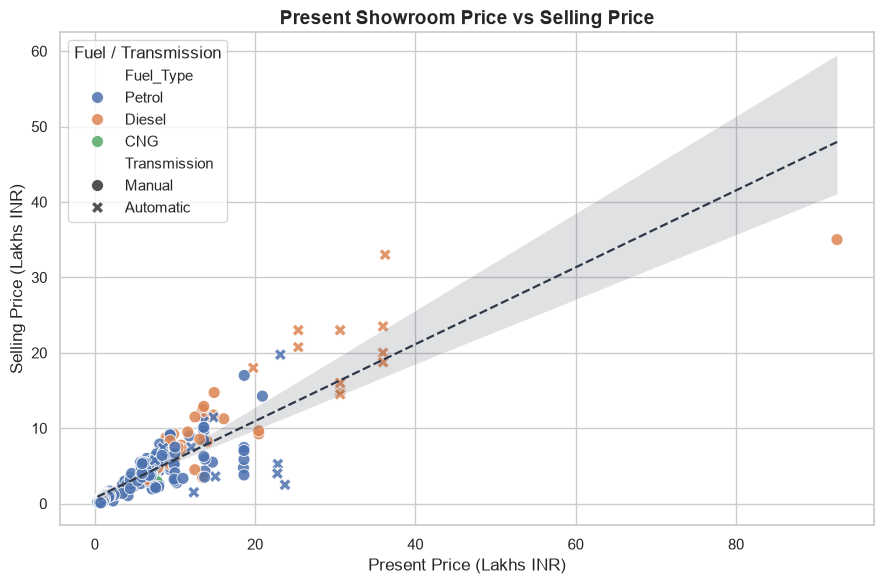

In [10]:
# 2. Present price vs selling price
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(
    data=eda_df,
    x="Present_Price",
    y="Selling_Price",
    hue="Fuel_Type",
    style="Transmission",
    s=75,
    alpha=0.85,
    ax=ax,
)
sns.regplot(
    data=eda_df,
    x="Present_Price",
    y="Selling_Price",
    scatter=False,
    color="#2d3748",
    line_kws={"linestyle": "--", "linewidth": 1.6, "label": "Linear Trend"},
    ax=ax,
)
ax.set_title("Present Showroom Price vs Selling Price", fontsize=14, fontweight="bold")
ax.set_xlabel("Present Price (Lakhs INR)")
ax.set_ylabel("Selling Price (Lakhs INR)")
ax.legend(title="Fuel / Transmission")
fig.tight_layout()
fig.savefig(VIS_PLOTS_DIR / "02_present_price_vs_selling_price.png", dpi=300, bbox_inches="tight")
plt.show()

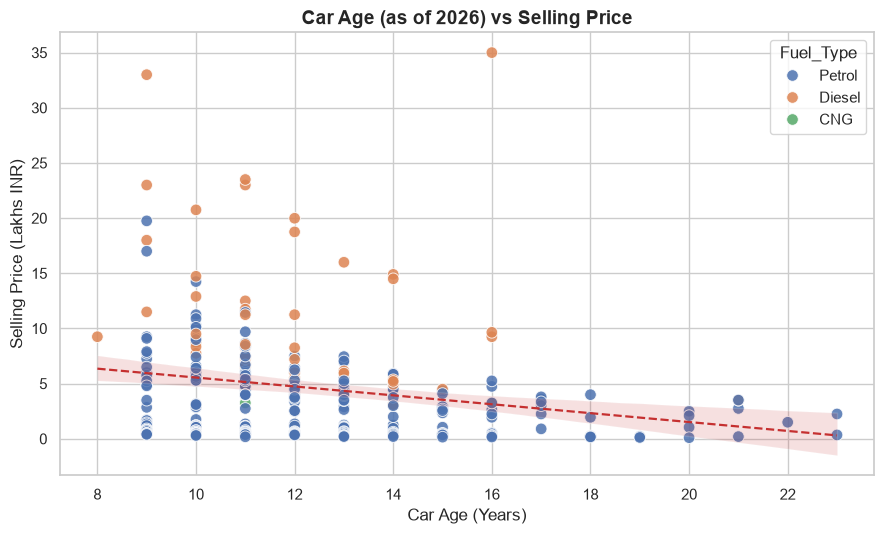

In [11]:
# 3. Car age vs selling price
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(
    data=eda_df,
    x="Car_Age",
    y="Selling_Price",
    hue="Fuel_Type",
    s=70,
    alpha=0.85,
    ax=ax,
)
sns.regplot(
    data=eda_df,
    x="Car_Age",
    y="Selling_Price",
    scatter=False,
    color="#c53030",
    line_kws={"linestyle": "--", "linewidth": 1.6},
    ax=ax,
)
ax.set_title(f"Car Age (as of {REFERENCE_YEAR}) vs Selling Price", fontsize=14, fontweight="bold")
ax.set_xlabel("Car Age (Years)")
ax.set_ylabel("Selling Price (Lakhs INR)")
fig.tight_layout()
fig.savefig(VIS_PLOTS_DIR / "03_car_age_vs_selling_price.png", dpi=300, bbox_inches="tight")
plt.show()

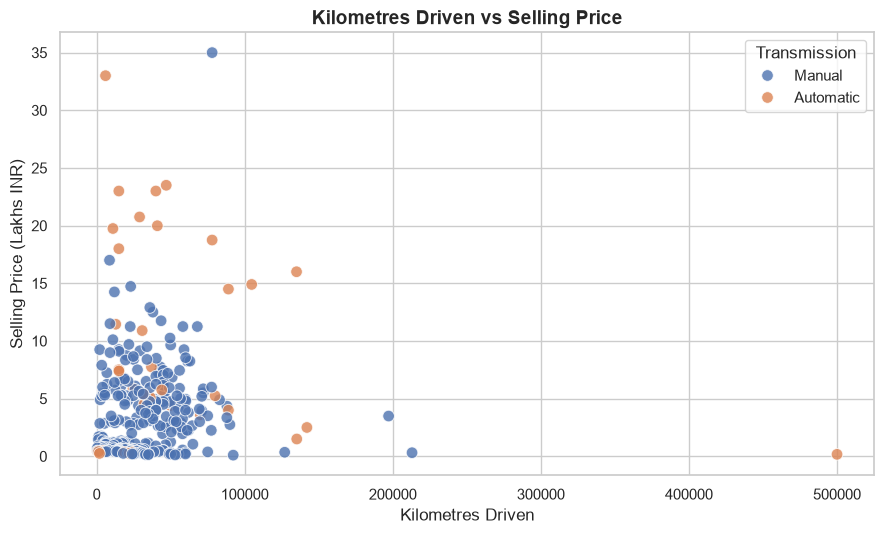

In [12]:
# 4. Kilometres driven vs selling price
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(
    data=eda_df,
    x="Kms_Driven",
    y="Selling_Price",
    hue="Transmission",
    s=70,
    alpha=0.8,
    ax=ax,
)
ax.set_title("Kilometres Driven vs Selling Price", fontsize=14, fontweight="bold")
ax.set_xlabel("Kilometres Driven")
ax.set_ylabel("Selling Price (Lakhs INR)")
fig.tight_layout()
fig.savefig(VIS_PLOTS_DIR / "04_kms_driven_vs_selling_price.png", dpi=300, bbox_inches="tight")
plt.show()

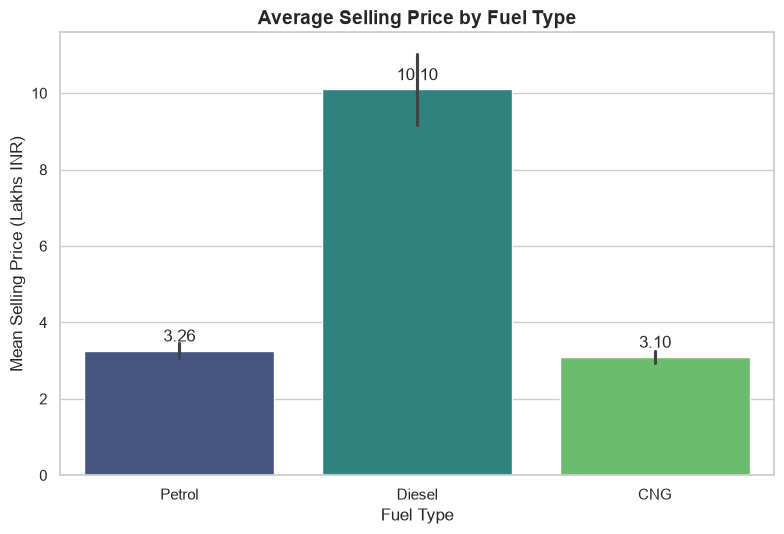

In [13]:
# 5. Fuel type vs selling price
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.barplot(
    data=eda_df,
    x="Fuel_Type",
    y="Selling_Price",
    hue="Fuel_Type",
    legend=False,
    estimator="mean",
    errorbar="se",
    palette="viridis",
    ax=ax,
)
ax.set_title("Average Selling Price by Fuel Type", fontsize=14, fontweight="bold")
ax.set_xlabel("Fuel Type")
ax.set_ylabel("Mean Selling Price (Lakhs INR)")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=4)
fig.tight_layout()
fig.savefig(VIS_PLOTS_DIR / "05_fuel_type_vs_selling_price.png", dpi=300, bbox_inches="tight")
plt.show()

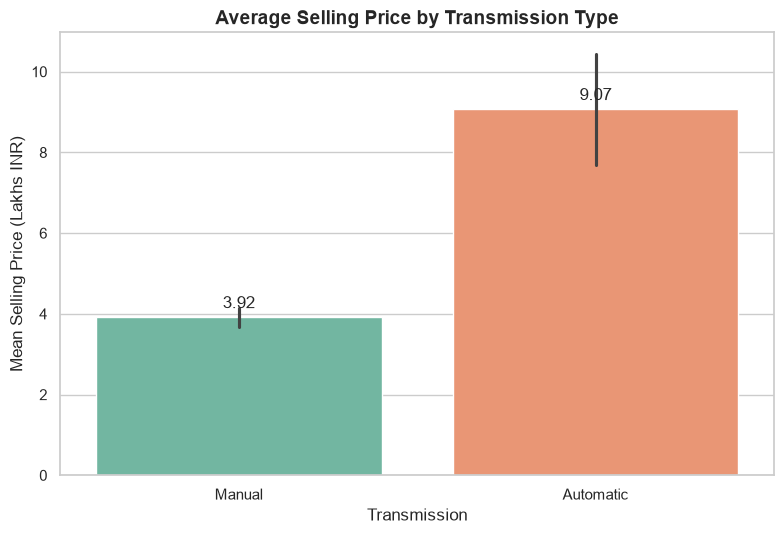

In [14]:
# 6. Transmission vs selling price
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.barplot(
    data=eda_df,
    x="Transmission",
    y="Selling_Price",
    hue="Transmission",
    legend=False,
    estimator="mean",
    errorbar="se",
    palette="Set2",
    ax=ax,
)
ax.set_title("Average Selling Price by Transmission Type", fontsize=14, fontweight="bold")
ax.set_xlabel("Transmission")
ax.set_ylabel("Mean Selling Price (Lakhs INR)")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=4)
fig.tight_layout()
fig.savefig(VIS_PLOTS_DIR / "06_transmission_vs_selling_price.png", dpi=300, bbox_inches="tight")
plt.show()

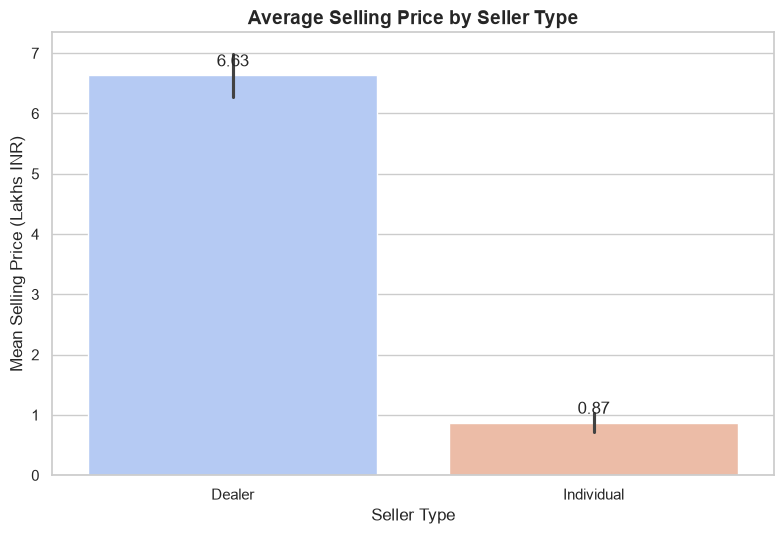

In [15]:
# 7. Seller type vs selling price
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.barplot(
    data=eda_df,
    x="Seller_Type",
    y="Selling_Price",
    hue="Seller_Type",
    legend=False,
    estimator="mean",
    errorbar="se",
    palette="coolwarm",
    ax=ax,
)
ax.set_title("Average Selling Price by Seller Type", fontsize=14, fontweight="bold")
ax.set_xlabel("Seller Type")
ax.set_ylabel("Mean Selling Price (Lakhs INR)")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=4)
fig.tight_layout()
fig.savefig(VIS_PLOTS_DIR / "07_seller_type_vs_selling_price.png", dpi=300, bbox_inches="tight")
plt.show()

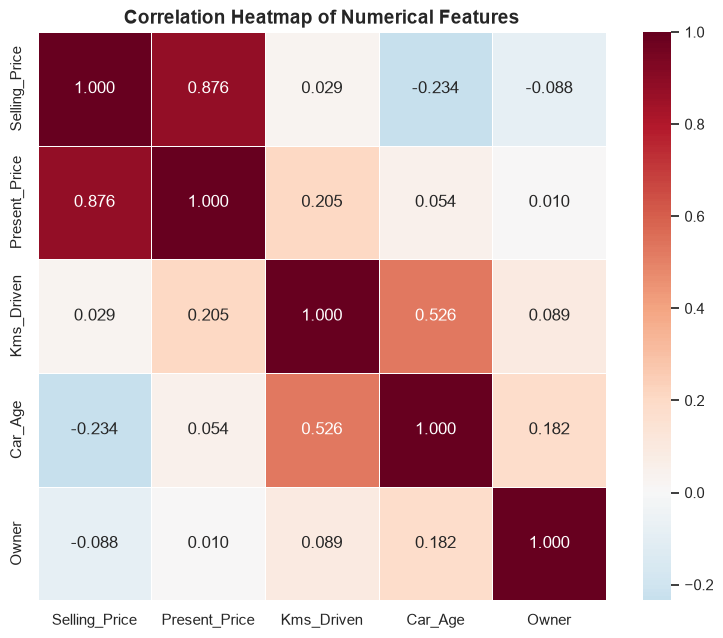

In [16]:
# 8. Correlation heatmap for numerical variables
corr_cols = ["Selling_Price", "Present_Price", "Kms_Driven", "Car_Age", "Owner"]
corr_matrix = eda_df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    square=True,
    ax=ax,
)
ax.set_title("Correlation Heatmap of Numerical Features", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(VIS_PLOTS_DIR / "08_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

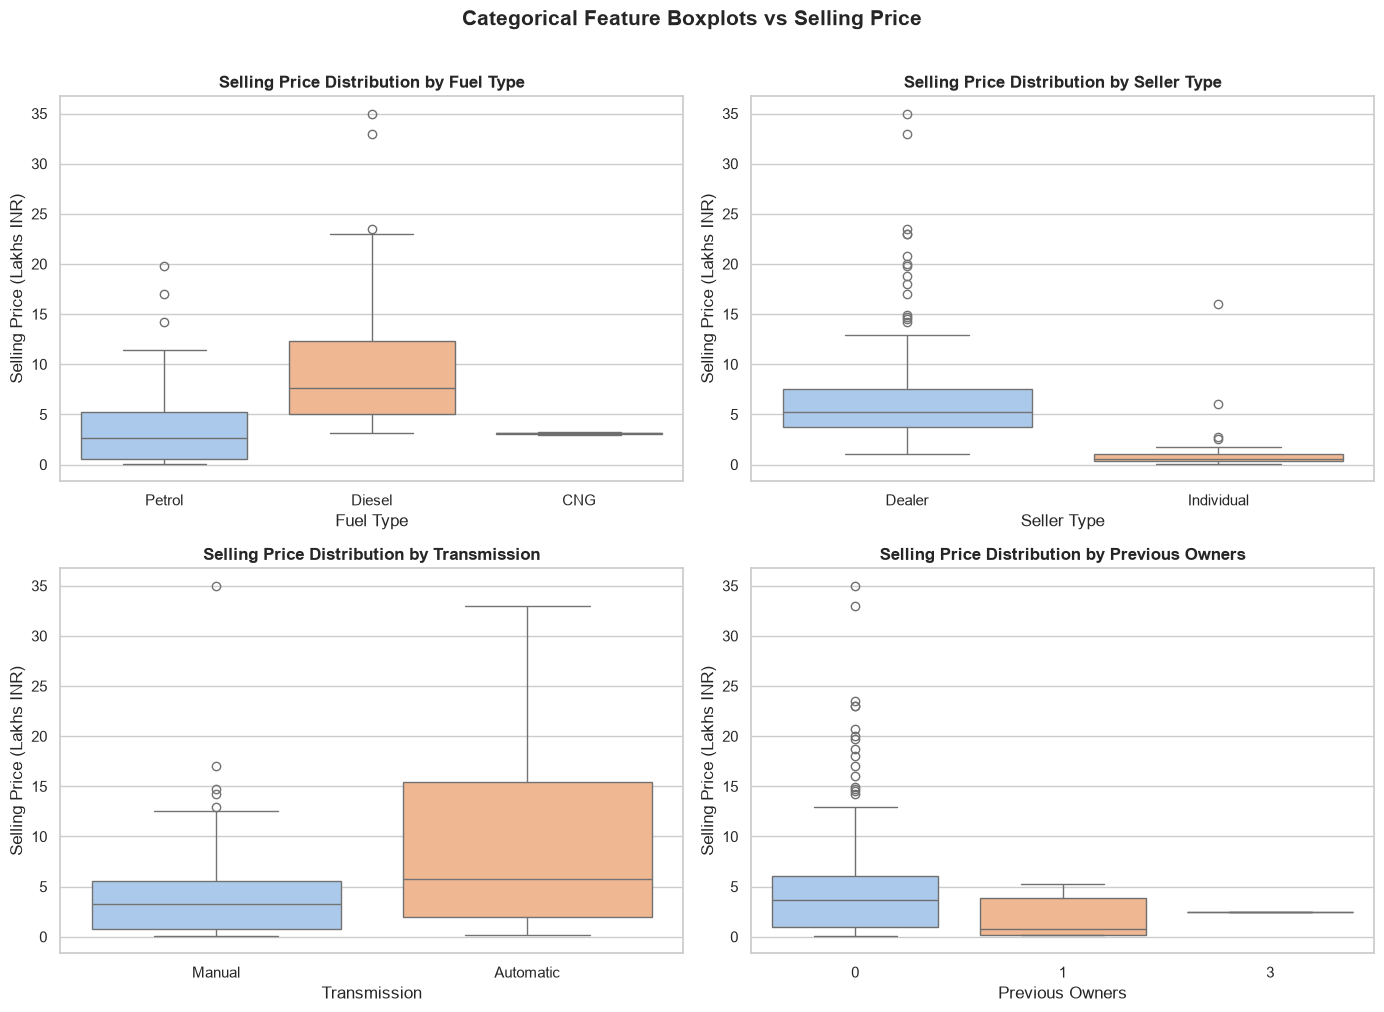

In [17]:
# 9. Boxplots for important categorical features
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
cat_specs = [
    ("Fuel_Type", "Fuel Type"),
    ("Seller_Type", "Seller Type"),
    ("Transmission", "Transmission"),
    ("Owner", "Previous Owners"),
]
for ax, (col, label) in zip(axes.ravel(), cat_specs):
    sns.boxplot(data=eda_df, x=col, y="Selling_Price", hue=col, legend=False, palette="pastel", ax=ax)
    ax.set_title(f"Selling Price Distribution by {label}", fontsize=12, fontweight="bold")
    ax.set_xlabel(label)
    ax.set_ylabel("Selling Price (Lakhs INR)")

fig.suptitle("Categorical Feature Boxplots vs Selling Price", fontsize=15, fontweight="bold", y=1.01)
fig.tight_layout()
fig.savefig(VIS_PLOTS_DIR / "09_categorical_boxplots.png", dpi=300, bbox_inches="tight")
plt.show()

### Exploratory Data Analysis Observations
1. **Strongest Predictor (`Present_Price`)**: `Present_Price` exhibits a high positive correlation with `Selling_Price` (`r = 0.876`), making original showroom price the primary anchor for resale value.
2. **Depreciation (`Car_Age`)**: `Car_Age` is negatively correlated with `Selling_Price` (`r = -0.234`) and positively correlated with `Kms_Driven` (`r = 0.526`). Newer vehicles command substantially higher resale values and retain a larger fraction of their showroom price.
3. **Fuel Type**: Diesel vehicles have a noticeably higher average selling price (`10.10` Lakhs INR) than Petrol (`3.26` Lakhs) or CNG (`3.10` Lakhs), largely because diesel engines dominate the higher-priced SUV/sedan segment.
4. **Transmission & Seller Type**: Automatic vehicles average higher selling prices (`9.07` Lakhs) than Manual vehicles (`3.92` Lakhs), and `Dealer` listings (`6.63` Lakhs) are substantially higher priced on average than `Individual` listings (`0.87` Lakhs, which include many two-wheelers).
5. **Kilometres Driven**: Very high mileage generally corresponds to lower resale prices, though high-priced SUVs retain value better than budget vehicles or two-wheelers.

## 6. Model Training, Cross-Validation & Comparison
We split the 299 unique records into an **80:20 train-test split** (`239` training, `60` test) stratified across `Selling_Price` quintiles so that both sets cover the full price range proportionally.

Five regression models are trained and evaluated inside leak-free `scikit-learn` pipelines (`StandardScaler` + `OneHotEncoder` + Estimator):
1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. Gradient Boosting Regressor
5. Extra Trees Regressor

We evaluate 5-fold cross-validation on the training set and holdout metrics (**MAE**, **MSE**, **RMSE**, **R² Score**) on the test set.

In [18]:
results = train_and_evaluate(save_outputs=True, show_plots=False)
comparison_df = results["comparison_df"]
print(f"Train samples: {len(results['X_train'])} | Test samples: {len(results['X_test'])}")
print(f"Best Model Selected: {results['best_model_name']}")
display(comparison_df)

Train samples: 239 | Test samples: 60
Best Model Selected: Gradient Boosting Regressor


,Model,CV_R2_Mean,CV_R2_Std,CV_RMSE_Mean,Train_R2,Test_MAE,Test_MSE,Test_RMSE,Test_R2
0,Gradient Boosting Regressor,0.8590,0.1065,1.7775,0.9970,0.6215,1.3932,1.1803,0.9072
1,Extra Trees Regressor,0.8629,0.0554,1.7972,1.0000,0.5946,1.4470,1.2029,0.9036
2,Linear Regression,0.7798,0.0801,2.2839,0.8828,1.1965,3.1208,1.7666,0.7921
3,Random Forest Regressor,0.8611,0.1110,1.7861,0.9890,0.8382,3.7620,1.9396,0.7494
4,Decision Tree Regressor,0.8700,0.0359,1.7833,1.0000,0.8728,4.6664,2.1602,0.6891


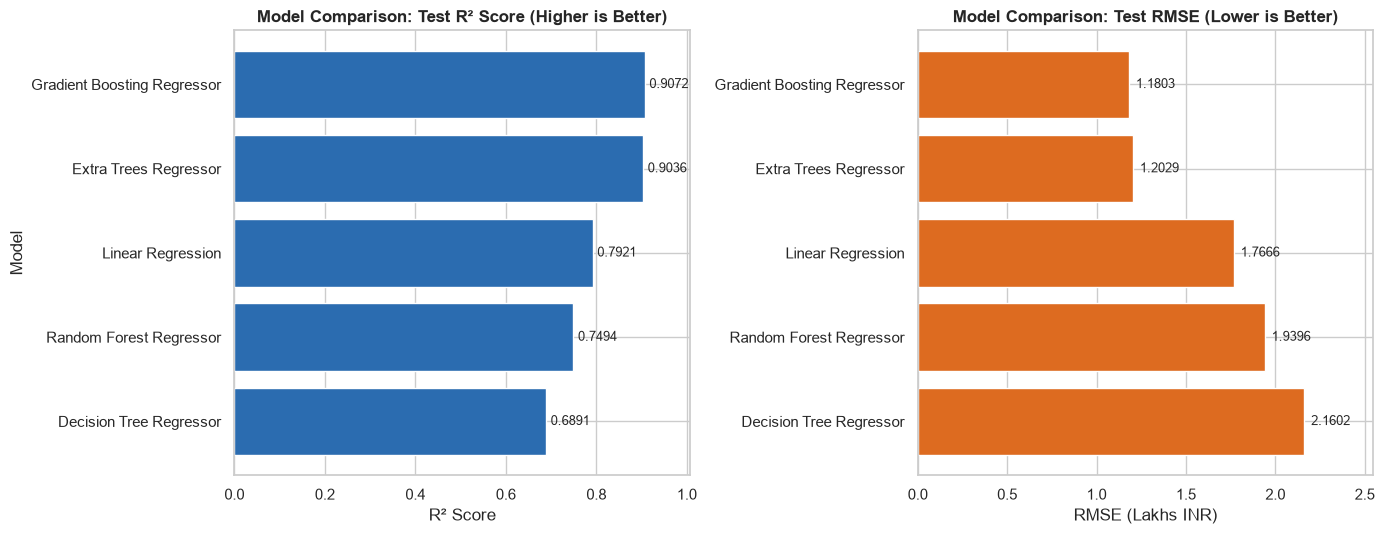

In [19]:
# Display Model Comparison Chart
fig = plot_model_comparison(comparison_df, show=True)

## 7. Model Evaluation, Residual Diagnostics & Feature Importance
We inspect the selected best model's predictions on the 60-sample holdout test set using:
- **Actual vs Predicted Selling Price**
- **Residual Distribution**
- **Residuals vs Predicted Values**
- **Feature Importance** (also saved as Chart #10 in `outputs/visualizations/10_feature_importance.png`)

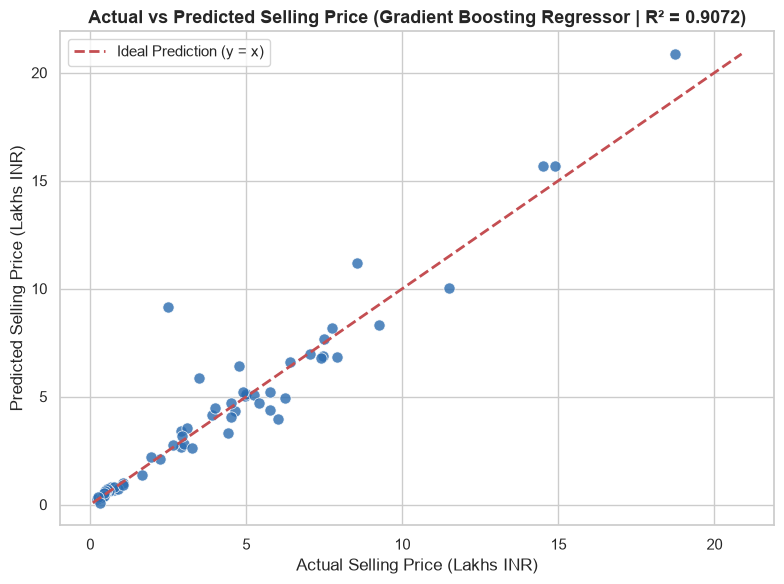

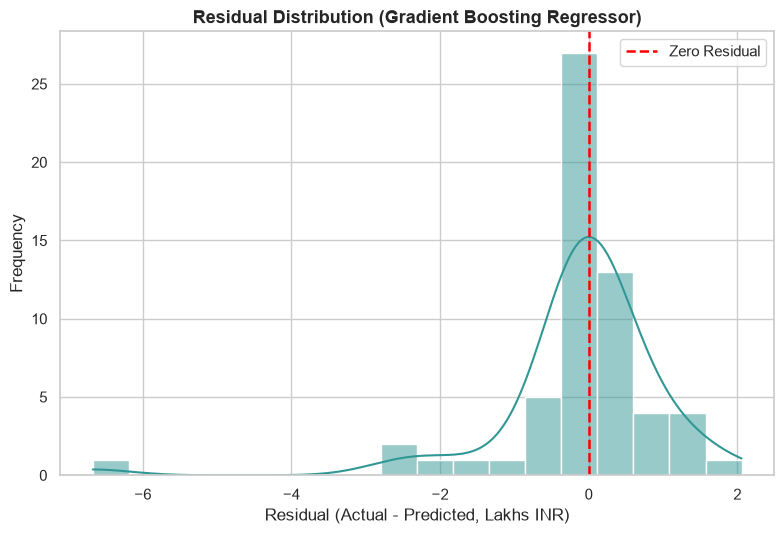

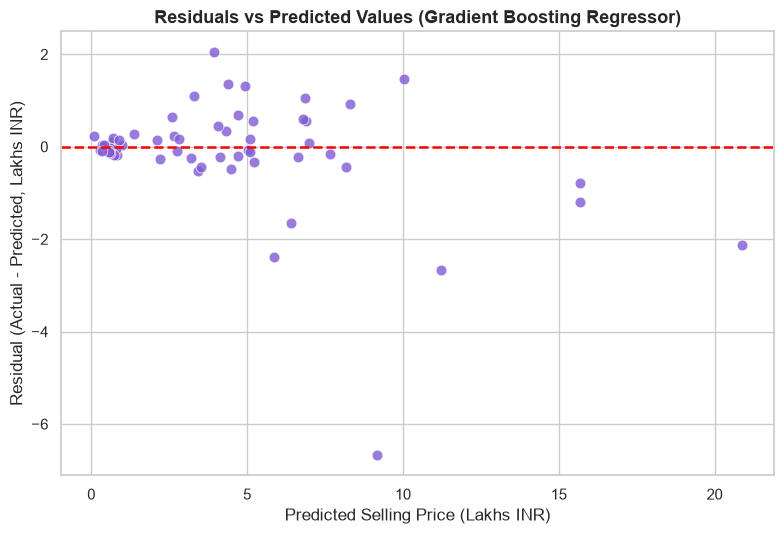

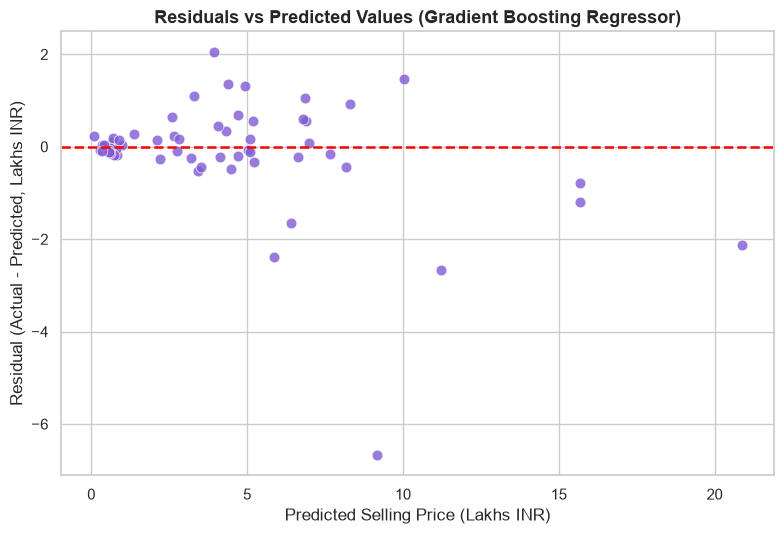

In [20]:
y_test = results["y_test"]
best_pred = results["best_test_pred"]
best_name = results["best_model_name"]

plot_actual_vs_predicted(y_test, best_pred, model_name=best_name, show=True)
plot_residual_distribution(y_test, best_pred, model_name=best_name, show=True)
plot_residuals_vs_predicted(y_test, best_pred, model_name=best_name, show=True)

,Feature,Importance
0,Present_Price,0.880277
1,Car_Age,0.076440
2,Kms_Driven,0.019929
3,Fuel_Type_Diesel,0.016807
4,Fuel_Type_Petrol,0.004849
5,Seller_Type_Dealer,0.001439
6,Transmission_Manual,0.000182
7,Transmission_Automatic,0.000061
8,Seller_Type_Individual,0.000017
9,Owner,0.000000


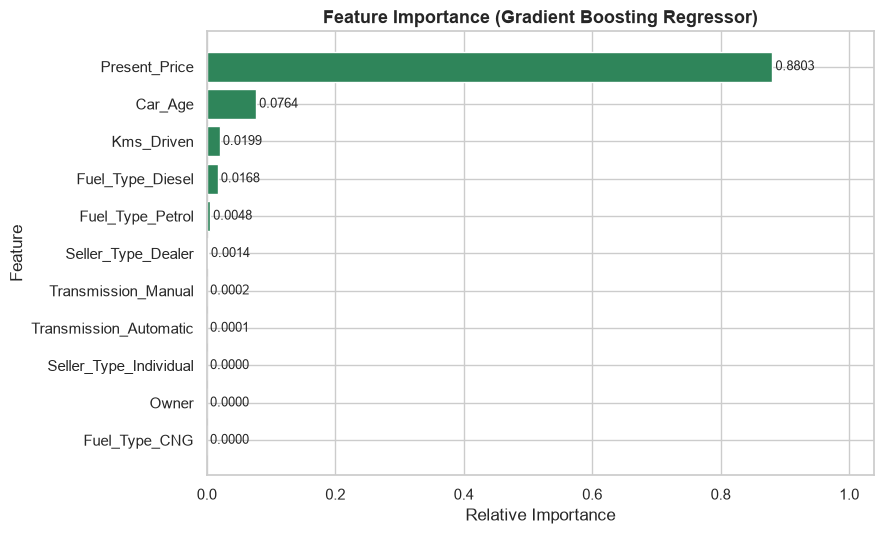

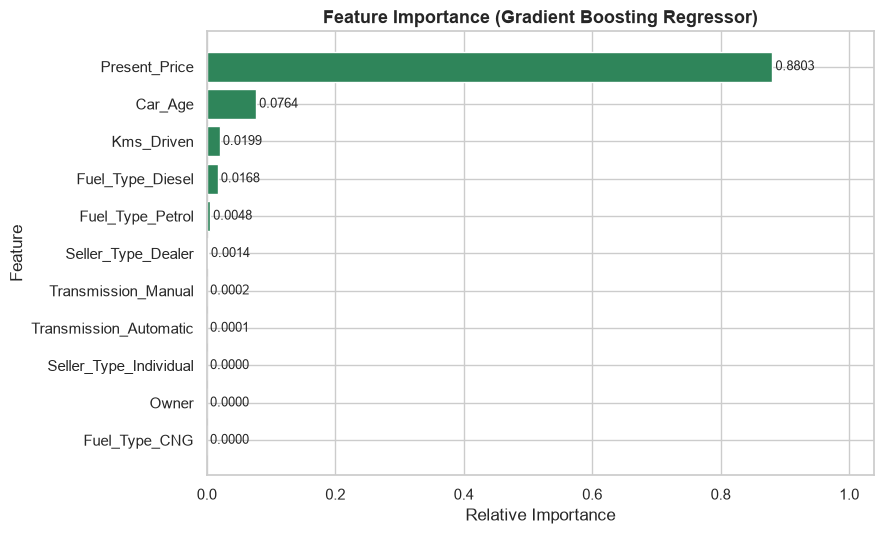

In [21]:
# 10. Feature importance visualization for the best suitable tree-based model
tree_imp_df = results["tree_importance_df"]
tree_model_name = results["tree_importance_model_name"]
display(tree_imp_df)
plot_feature_importance(tree_imp_df, model_name=tree_model_name, show=True)

### Model Evaluation Observations
- **Best Model Performance**: **Gradient Boosting Regressor** achieves the highest test-set **R² = 0.9072** with **MAE = 0.6215 Lakhs INR** and **RMSE = 1.1803 Lakhs INR**, closely followed by **Extra Trees Regressor** (**R² = 0.9036**, **MAE = 0.5946**, **RMSE = 1.2029**).
- **Generalization vs Overfitting**: A single Decision Tree overfits the training fold (`Train_R2 = 1.0000` vs `Test_R2 = 0.6891`), whereas ensemble boosting/randomization reduces variance dramatically (`0.9072` / `0.9036`).
- **Feature Importance**: `Present_Price` (`0.8803`) is overwhelmingly the most influential predictor, followed by `Car_Age` (`0.0764`), `Kms_Driven` (`0.0199`), and `Fuel_Type_Diesel` (`0.0168`).
- **Residual Analysis**: Most residuals cluster tightly around 0 Lakhs INR. The single largest negative residual occurs on an unusual 2006 `camry` (`Owner = 3`, `142,000` km, `Present_Price = 23.73`, `Actual = 2.50` vs `Predicted = 9.17`), because `Owner = 3` appears only once in the entire dataset.

## 8. Saved Model & Test Prediction Results
We verify the saved Joblib bundle (`models/best_car_price_model.joblib`) and inspect the exported test-set predictions (`outputs/prediction_results.csv`).

In [22]:
pred_results_df = pd.read_csv(OUTPUTS_DIR / "prediction_results.csv")
print(f"Saved model exists: {DEFAULT_MODEL_PATH.exists()} ({DEFAULT_MODEL_PATH.name})")
print(f"Test predictions rows: {len(pred_results_df)}")
display(pred_results_df.head(10))

Saved model exists: True (best_car_price_model.joblib)
Test predictions rows: 60


,Car_Name,Year,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Car_Age,Actual_Selling_Price,Predicted_Selling_Price,Residual,Absolute_Error
0,ertiga,2016,10.79,43000,Diesel,Dealer,Manual,0,10,7.75,8.1879,-0.4379,0.4379
1,i20,2017,8.10,3435,Petrol,Dealer,Manual,0,9,7.90,6.8499,1.0501,1.0501
2,verna,2012,9.40,60000,Diesel,Dealer,Manual,0,14,4.95,5.0156,-0.0656,0.0656
3,city,2013,9.90,56701,Petrol,Dealer,Manual,0,13,5.00,5.1091,-0.1091,0.1091
4,corolla altis,2013,18.61,45000,Petrol,Dealer,Manual,0,13,7.05,6.9743,0.0757,0.0757
5,camry,2006,23.73,142000,Petrol,Individual,Automatic,3,20,2.50,9.1721,-6.6721,6.6721
6,Royal Enfield Thunder 350,2011,1.50,6900,Petrol,Individual,Manual,0,15,1.05,1.0035,0.0465,0.0465
7,wagon r,2013,4.41,56879,Petrol,Dealer,Manual,0,13,2.90,2.6591,0.2409,0.2409
8,Bajaj Pulsar 150,2015,0.74,5000,Petrol,Individual,Manual,0,11,0.65,0.8199,-0.1699,0.1699
9,Honda Activa 4G,2017,0.51,4300,Petrol,Individual,Automatic,0,9,0.48,0.5475,-0.0675,0.0675


## 9. Car Price Prediction Demonstration (Using Saved Model)
We now load the saved pipeline via `predict_car_price()`—without retraining—and generate predictions for realistic vehicle profiles supported by the dataset.

In [23]:
sample_1 = dict(SAMPLE_CAR_INPUT)
res_1 = predict_car_price(sample_1)

sample_2 = {
    "Car_Name": "fortuner",
    "Year": 2015,
    "Present_Price": 30.61,
    "Kms_Driven": 40000,
    "Fuel_Type": "Diesel",
    "Seller_Type": "Dealer",
    "Transmission": "Automatic",
    "Owner": 0,
}
res_2 = predict_car_price(sample_2)

sample_3 = {
    "Car_Name": "Royal Enfield Classic 350",
    "Year": 2016,
    "Present_Price": 1.47,
    "Kms_Driven": 12000,
    "Fuel_Type": "Petrol",
    "Seller_Type": "Individual",
    "Transmission": "Manual",
    "Owner": 0,
}
res_3 = predict_car_price(sample_3)

for idx, res in enumerate([res_1, res_2, res_3], start=1):
    print(f"Sample {idx} ({res['input_features']['Car_Name']}, {res['input_features']['Year']}):")
    print(f"  Model Used              : {res['model_name']}")
    print(f"  Derived Car Age         : {res['car_age']} years")
    print(f"  Predicted Selling Price : {res['predicted_selling_price']:.2f} {res['unit']}\n")

Sample 1 (ciaz, 2017):
  Model Used              : Gradient Boosting Regressor
  Derived Car Age         : 9 years
  Predicted Selling Price : 7.85 Lakhs INR

Sample 2 (fortuner, 2015):
  Model Used              : Gradient Boosting Regressor
  Derived Car Age         : 11 years
  Predicted Selling Price : 22.94 Lakhs INR

Sample 3 (Royal Enfield Classic 350, 2016):
  Model Used              : Gradient Boosting Regressor
  Derived Car Age         : 10 years
  Predicted Selling Price : 1.17 Lakhs INR



## 10. Conclusion
This project successfully built and validated an end-to-end machine learning pipeline for used car price prediction on the CarDekho dataset:
- **Gradient Boosting Regressor** emerged as the top-performing model (`Test R² = 0.9072`, `RMSE = 1.1803`, `MAE = 0.6215`), outperforming Linear Regression, Decision Tree, Random Forest, and slightly edging out Extra Trees Regressor.
- **Present Showroom Price** and **Car Age** are the dominant drivers of used vehicle resale value.
- All preprocessing, training, evaluation, and prediction steps are modularized in `src/` and persisted cleanly in `models/best_car_price_model.joblib` for immediate reuse.